# Step 0. Load data and compute missing metrics & rolling means

In [124]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.spatial.distance import pdist

sns.set_context("talk")


VIDEO_FOLDER = "/home/bw/Projects/c02-fish/Videos"
pd.set_option('display.max_columns', None)
DATA_FOLDER = "tracking_output/"

In [168]:
# Loads the data.
# 
# This reads the csvs individually, adds identifying columns, and then
# at the end concatenates them all into one table and deletes the originals to save memory.
#
# Arguably this is a little fragile, but this way of doing it
# is at least explicit and lets us mark the columns. So no need to get fancy here.

dfs = []
for river in ["Green", "Skagit"]:
    for pH in [1, 2, 3]:
        for trial in range(1, 11):
            # DATA_FOLDER = VIDEO_FOLDER + f"/River-{river}/pH-{pH}/Trial-{trial}/data/"
            for individual in range(0, 6):
                try:
                    indiv = pd.read_csv(DATA_FOLDER + f"River-{river}-pH-{pH}-Trial-{trial}_id{individual}.csv")
                    indiv["River"] = river
                    indiv["pH"] = pH
                    indiv["Trial"] = trial
                    indiv["Individual"] = individual
                    dfs.append(indiv)
                except:
                    # Pretty noisy, but this lives on as a loud TODO to get these missing videos tracked.
                    print("skipping", f"River-{river}-pH-{pH}-Trial-{trial}_id{individual}.")

df = pd.concat(dfs, ignore_index=True)
del(dfs)

# This reads the event times (skin extraction & visual disturbance) and then merges these columns in.
# It's more like an SQL join, but pandas calls it `merge`.
event_times = pd.read_csv("event_times.csv")
df = df.merge(event_times, on=["River", "pH", "Trial"])


def to_seconds(s):
    """Converts a string like `25:15` to a number of seconds."""
    m, s = s.split(":")
    return int(m) * 60 + int(s)

# Tests for to_seconds().
assert to_seconds("25:15") == 25 * 60 + 15
assert to_seconds("1:15") == 75

# Go through and convert these strings to seconds.
df["skin_extract_injection_seconds"] = df["Skin extract injection (Video run time)"].apply(to_seconds)
df["visual_disturbance_seconds"] = df["Visual disturbance (Video run time)"].apply(to_seconds)

# Adds columns of time _relative to these events_.
df["skin_extract_injection_time"] = df["time"] - df["skin_extract_injection_seconds"]
df["visual_disturbance_time"] = df["time"] - df["visual_disturbance_seconds"]


# Adds rolling means.
NAMES = [
    ("borderdist", "BORDER_DISTANCE#pcentroid (cm)"),
    ("speed", "SPEED#wcentroid (cm/s)"),
    ("pspeed", "SPEED#pcentroid (cm/s)"),
]
ROLLING_MEAN_FRAMES = [15, 60, 240]

for short_name, col_name in NAMES:
    for i in ROLLING_MEAN_FRAMES:
        print(f"\r{short_name} {i}", end="          ")
        df[f"{short_name}{i}"] = df.groupby(
            ["River", "pH", "Trial", "Individual"]).rolling(i)[col_name].mean().reset_index(drop=True)

# **************************
# Downsamples to 1 second
# *************************
# I'm making the comment big because this is important but a small line of code.
# 
# We only want to keep data for every second. There's really no need to be more fine-grained than
# this IMO, it makes everything way slower.
df = df[df["time"] % 1.0 == 0]

# Add neighbor distances at every second (not every frame).
data = []

i = 0
for _name, group_df in df.groupby(["River", "pH", "Trial", "time"]):
    river, pH, trial, time = _name
    # TODO(brendan): why are some of these empty? And what is the returned value when they are?
    # Check whether they're empty and if necessary apply a more appropriate missing value.
    fish_positions = group_df[["X (cm)", "Y (cm)"]].to_numpy()
    # print(raw_values.shape)

    if fish_positions.shape == (6, 2):
        mean_neighbor_dist = np.mean(pdist(fish_positions))
        min_neighbor_dist = np.min(pdist(fish_positions))
    else:
        mean_neighbor_dist = np.nan
    data.append((river, pH, trial, time, mean_neighbor_dist, min_neighbor_dist))


# # Another merge/join to get the neighbor dists into the larger dataframe.
by_trial = pd.DataFrame(data, columns = ["River", "pH", "Trial", "time", "meanneighbordist", "minneighbordist"])
df = df.merge(by_trial, on=["River", "pH", "Trial", "time"])
del(by_trial) # These dataframes are big and this is running on my macbook air. So let's clean up things we're not using.

skipping River-Green-pH-2-Trial-2_id0.
skipping River-Green-pH-2-Trial-2_id1.
skipping River-Green-pH-2-Trial-2_id2.
skipping River-Green-pH-2-Trial-2_id3.
skipping River-Green-pH-2-Trial-2_id4.
skipping River-Green-pH-2-Trial-2_id5.
skipping River-Skagit-pH-1-Trial-9_id2.
skipping River-Skagit-pH-1-Trial-9_id4.
skipping River-Skagit-pH-2-Trial-2_id0.
skipping River-Skagit-pH-2-Trial-5_id0.
skipping River-Skagit-pH-2-Trial-5_id1.
skipping River-Skagit-pH-2-Trial-5_id2.
skipping River-Skagit-pH-2-Trial-5_id3.
skipping River-Skagit-pH-2-Trial-5_id4.
skipping River-Skagit-pH-2-Trial-5_id5.
skipping River-Skagit-pH-2-Trial-6_id0.
skipping River-Skagit-pH-2-Trial-6_id1.
skipping River-Skagit-pH-2-Trial-6_id2.
skipping River-Skagit-pH-2-Trial-6_id3.
skipping River-Skagit-pH-2-Trial-6_id4.
skipping River-Skagit-pH-2-Trial-6_id5.
skipping River-Skagit-pH-2-Trial-7_id0.
skipping River-Skagit-pH-2-Trial-7_id1.
skipping River-Skagit-pH-2-Trial-7_id2.
skipping River-Skagit-pH-2-Trial-7_id3.
skippi

In [174]:
# Add neighbor distances at every second (not every frame).
data = []

i = 0
for _name, group_df in df.groupby(["River", "pH", "Trial", "time"]):
    river, pH, trial, time = _name
    # TODO(brendan): why are some of these empty? And what is the returned value when they are?
    # Check whether they're empty and if necessary apply a more appropriate missing value.
    fish_positions = group_df[["X (cm)", "Y (cm)"]].to_numpy()
    # print(raw_values.shape)

    if fish_positions.shape == (6, 2):
        mean_neighbor_dist = np.mean(pdist(fish_positions))
        min_neighbor_dist = np.min(pdist(fish_positions))
    else:
        mean_neighbor_dist = np.nan
    data.append((river, pH, trial, time, mean_neighbor_dist, min_neighbor_dist))


# # Another merge/join to get the neighbor dists into the larger dataframe.
# TODO -- why is this join leading to duplicated values?
by_trial = pd.DataFrame(data, columns = ["River", "pH", "Trial", "time", "meanneighbordist", "minneighbordist"])

In [189]:
df["visual_identification_p"].unique()

array([inf])

In [187]:
by_trial.shape

(103814, 6)

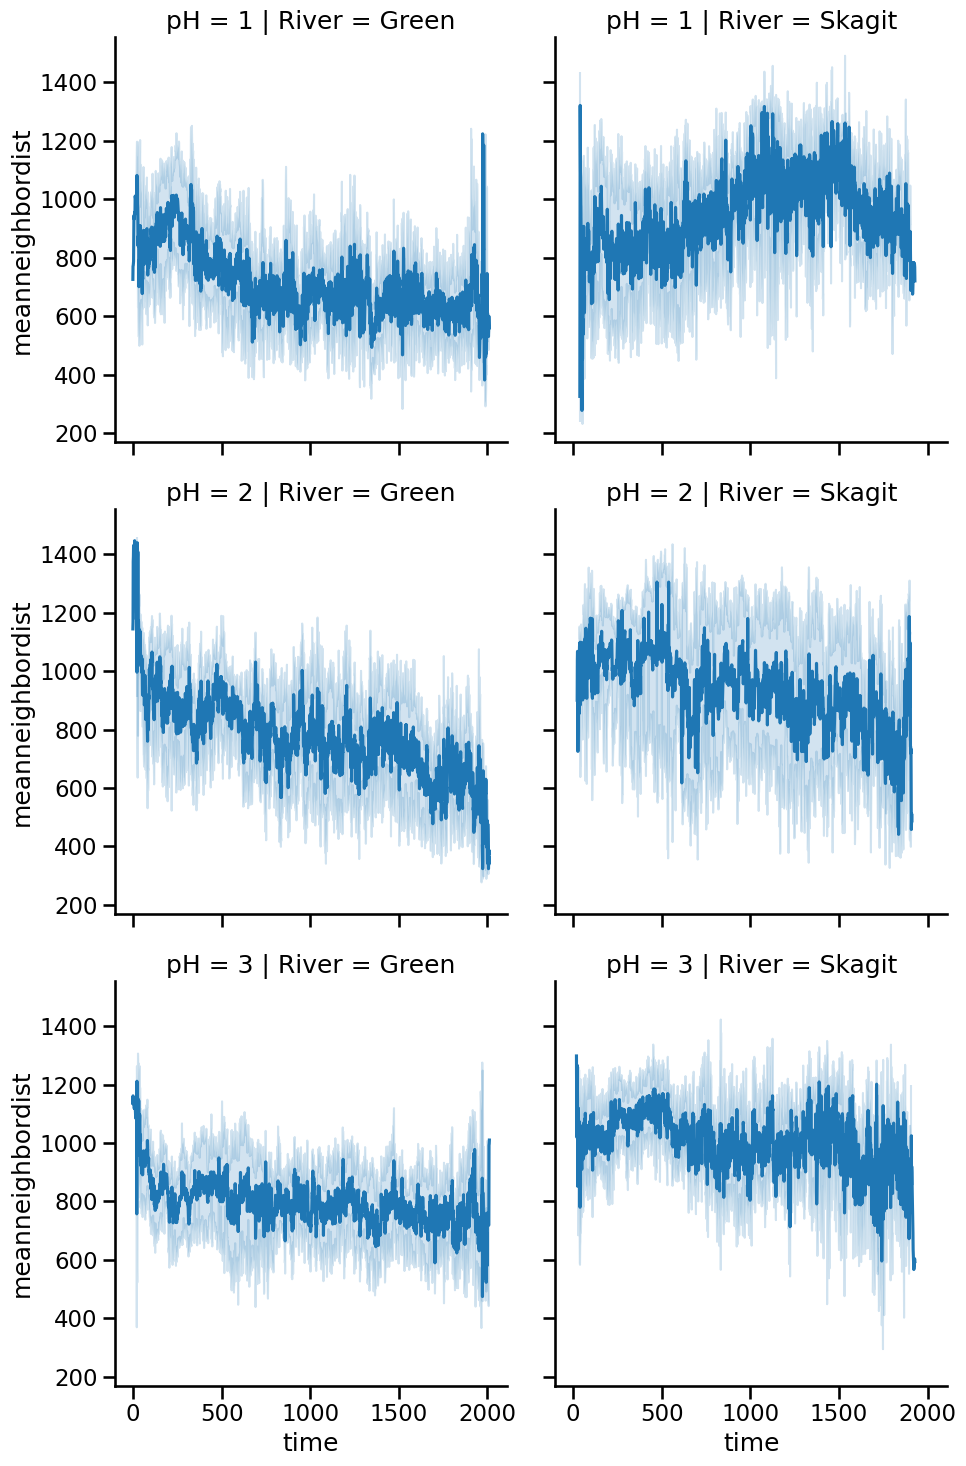

In [176]:
for var in ["meanneighbordist"]:
    p = sns.relplot(data=by_trial, x="time", y=var, kind="line", col="River", row="pH", hue="Trial")

# Step 1. Qualitative analysis.

- One for each variable of interest (speed, mean distance btw. neighbors, radial pos)
- look at 3 different time series
- relaxation at the start (0 - ?)
- time series around the alarm (-? - +?)
- time series around the startle event (-? - +?)
- 6 different curves. average these. one for each Ph.
- or two panels.


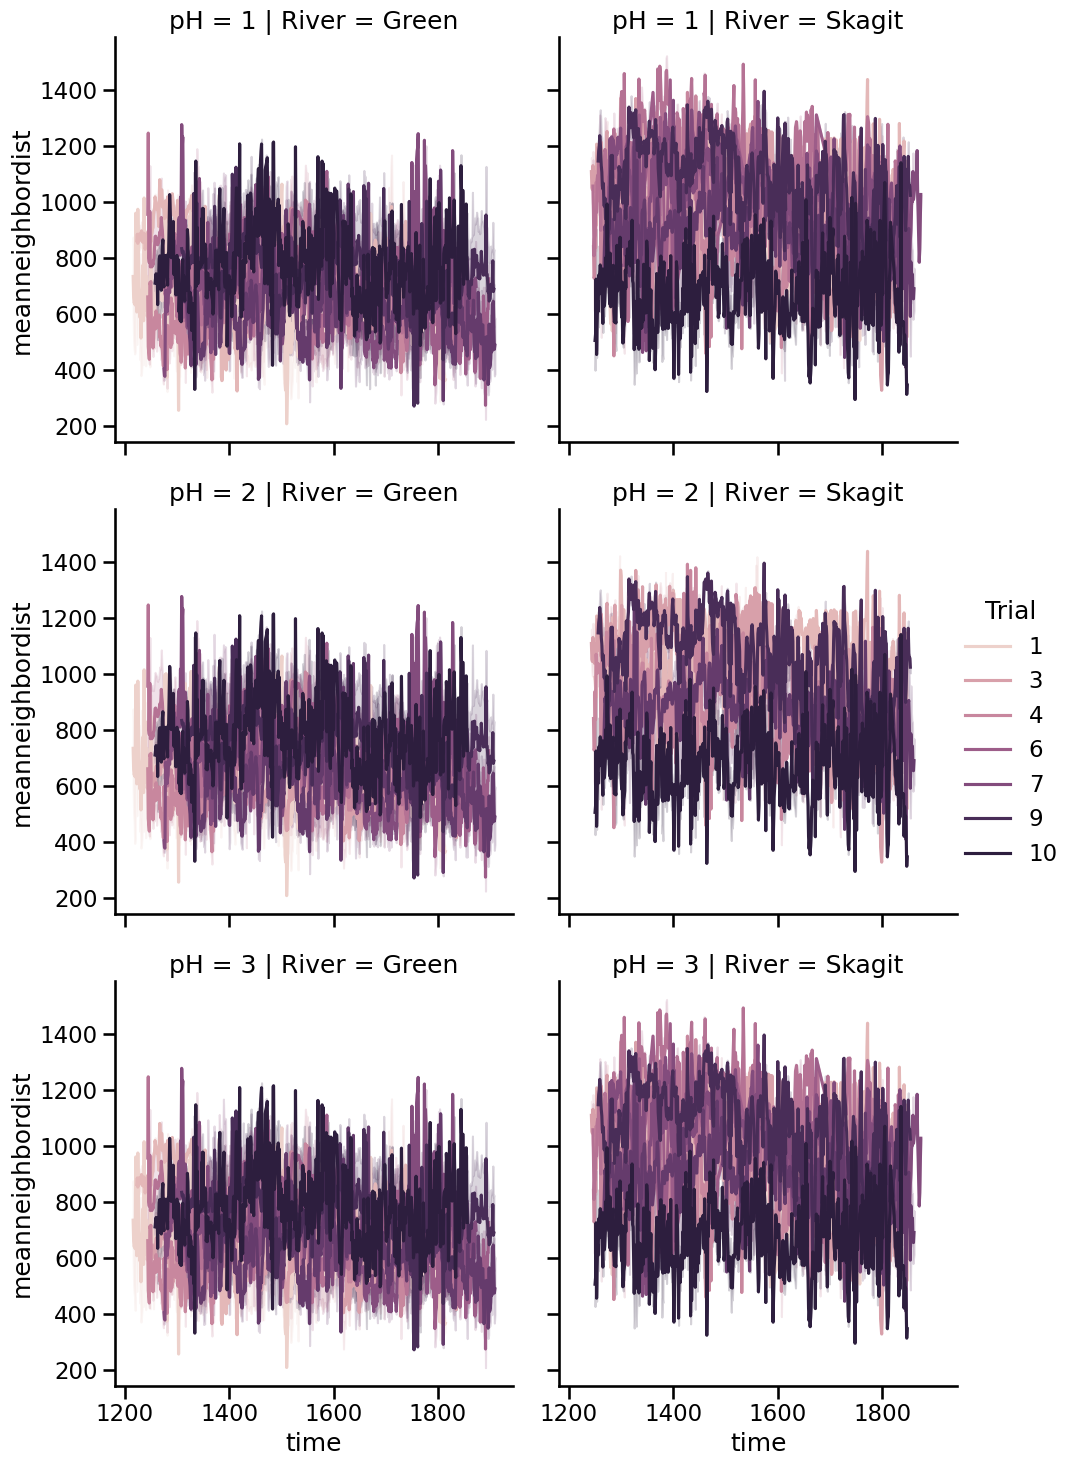

In [165]:
# First 10 minutes
first_10 = df[
    (df["time"] > 0) &
    (df["time"] < 60 * 10)]

for var in ["meanneighbordist"]:
    p = sns.relplot(data=_df, x="time", y=var, kind="line", col="River", row="pH", hue="Trial")


KeyboardInterrupt: 

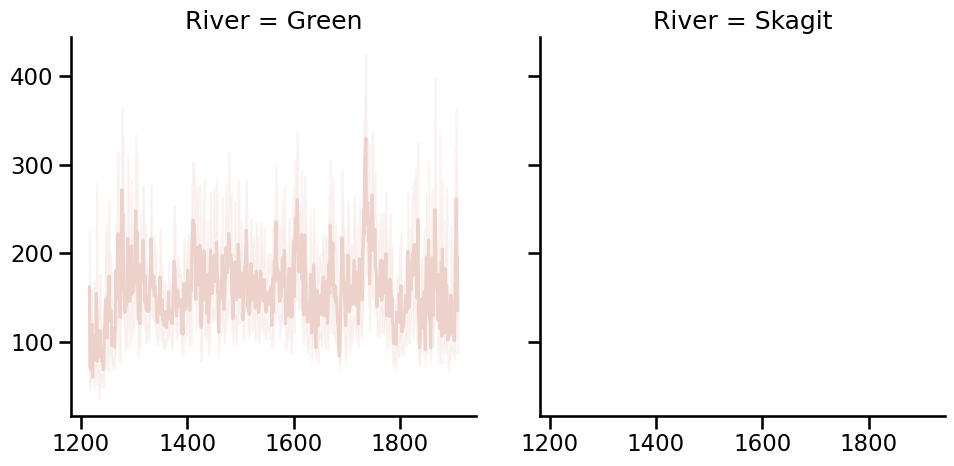

In [172]:
# First 10 minutes
first_10 = df[
    (df["time"] > 0) &
    (df["time"] < 60 * 10)]


for var in ["speed15", "borderdist15", "meanneighbordist", "minneighbordist"]:
    p = sns.relplot(data=_df, x="time", y=var, kind="line", col="River", hue="pH")


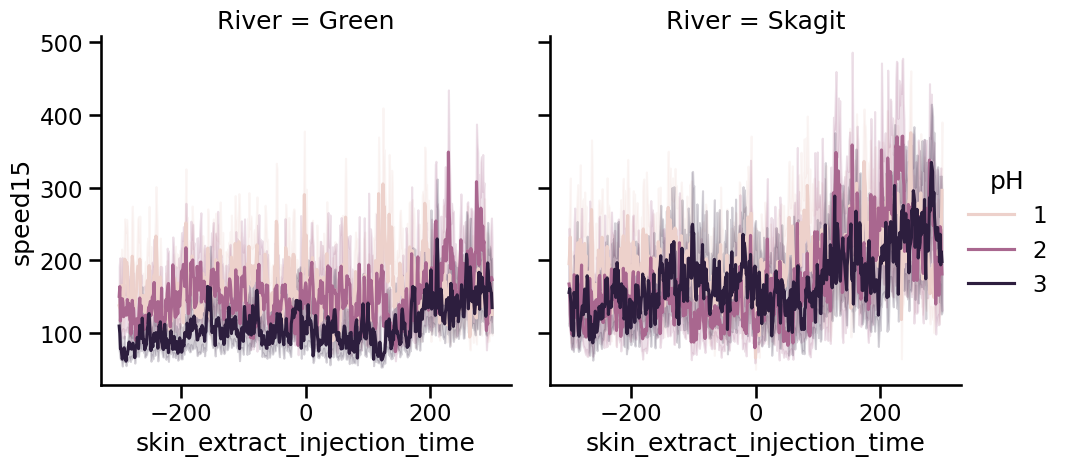

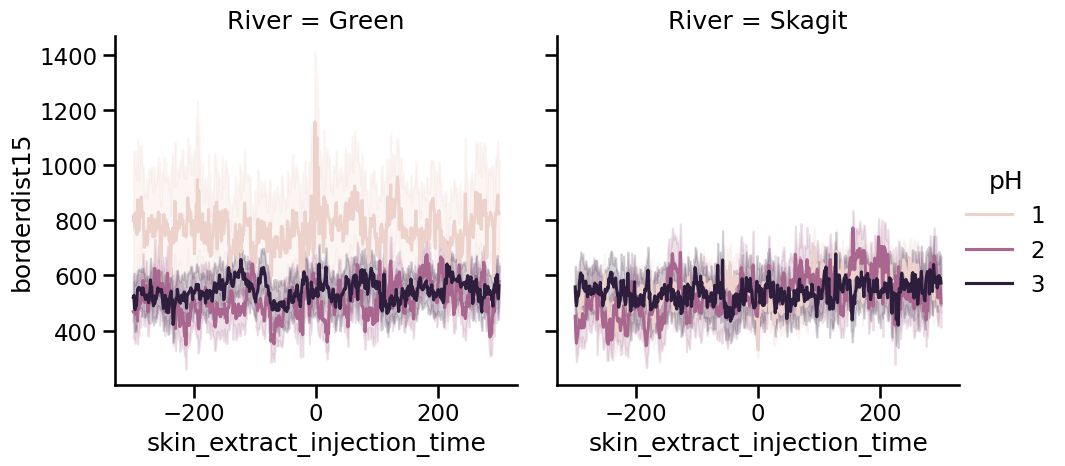

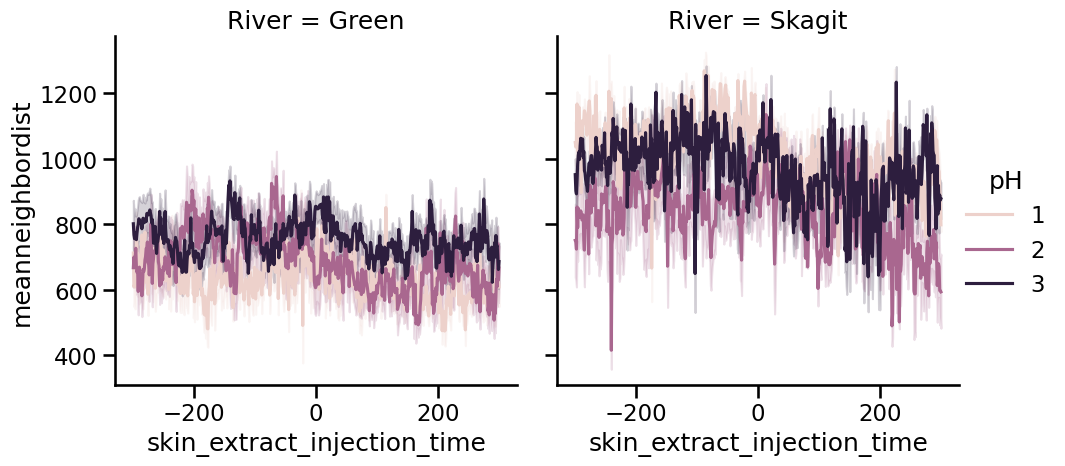

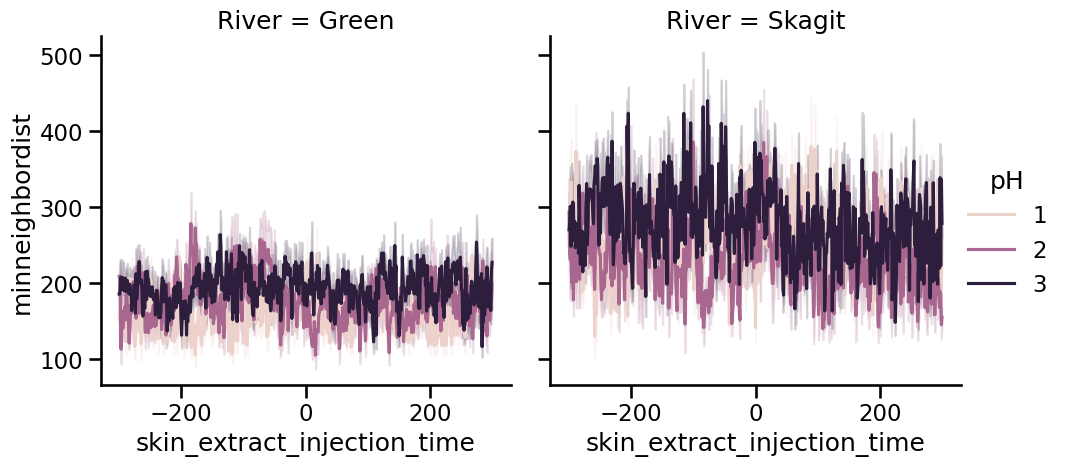

In [195]:
# 5 minutes before and after skin extract injection.
_df = df[
    (df["skin_extract_injection_time"] % 1.0 == 0) &
    (df["skin_extract_injection_time"] > -60 * 5) &
    (df["skin_extract_injection_time"] < 60 * 5)]

for var in ["speed15", "borderdist15", "meanneighbordist", "minneighbordist"]:
    p = sns.relplot(data=_df, x="skin_extract_injection_time", y=var, kind="line", col="River", hue="pH")

In [ ]:
# 5 minutes before and 2 after the visual disturbance.
_df = df[
    (df["visual_disturbance_time"] % 1.0 == 0) &
    (df["visual_disturbance_time"] > -60 * 5) &
    (df["visual_disturbance_time"] < 60 * 2)
    ]


for var in ["speed15", "borderdist15", "meanneighbordist"]:
    p = sns.relplot(data=_df, x="visual_disturbance_time", y=var, kind="line", col="River", hue="pH")

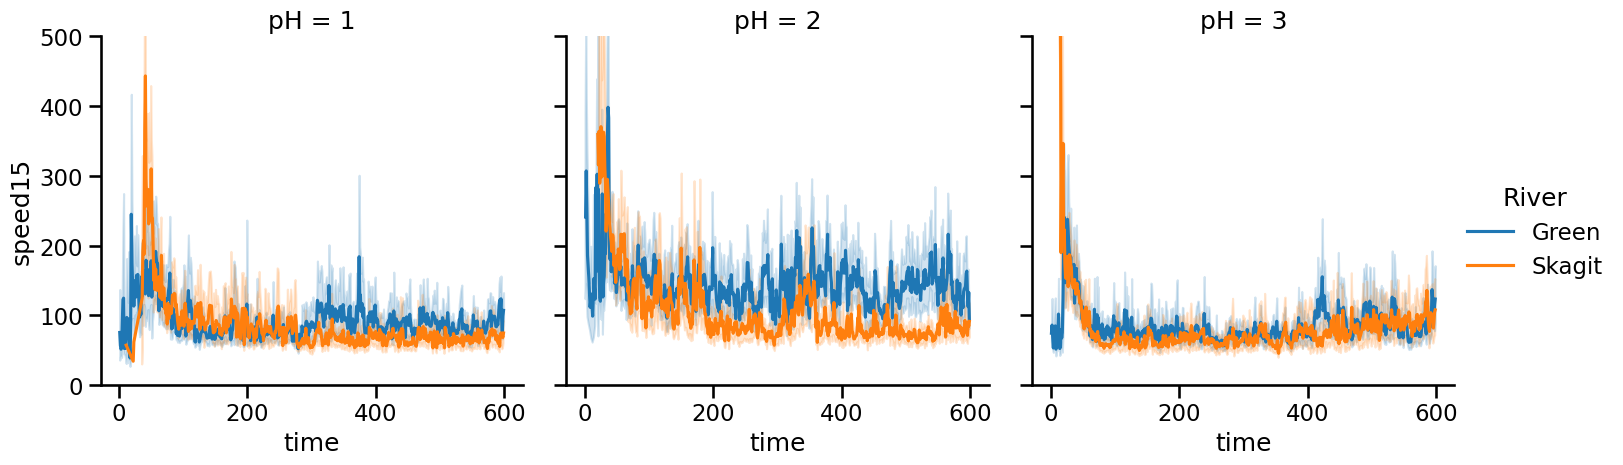

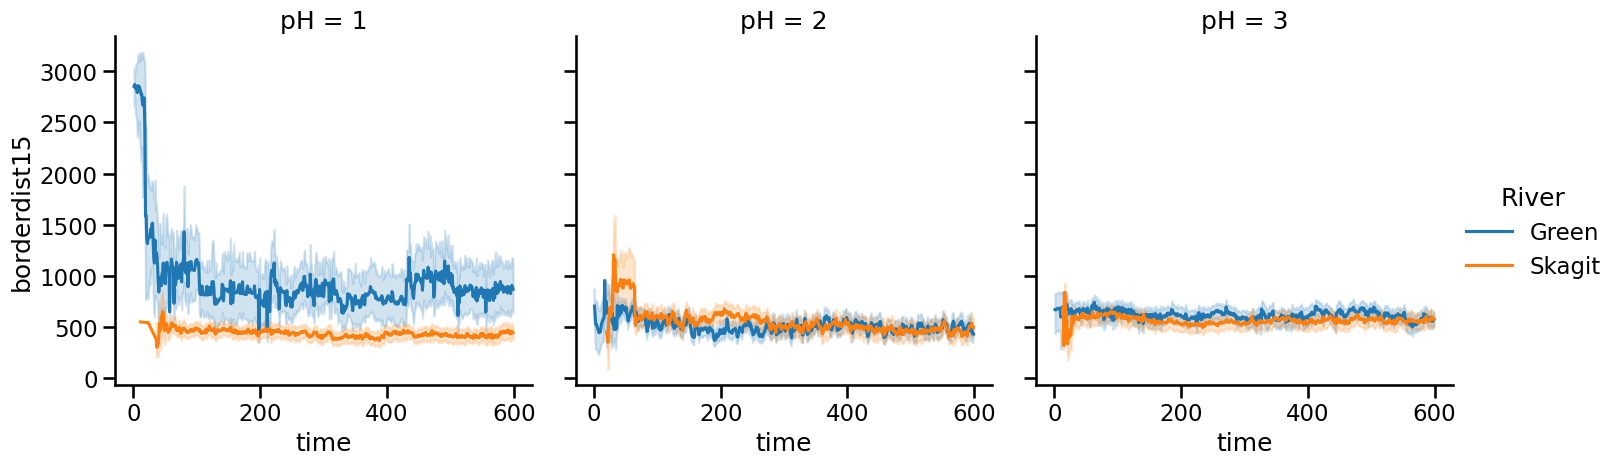

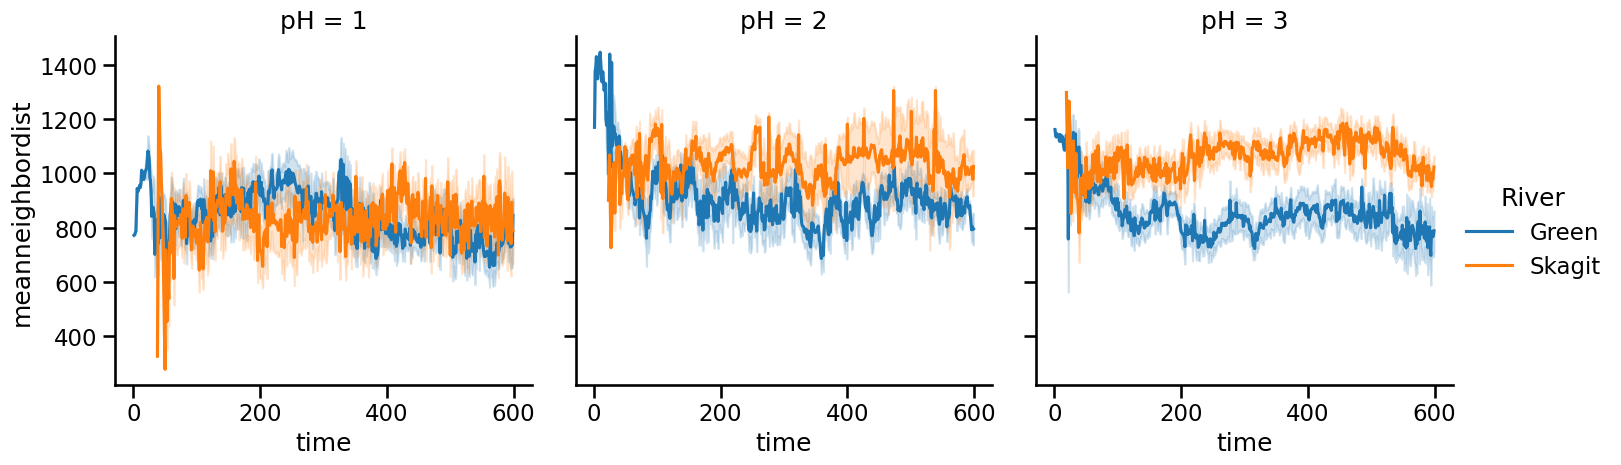

In [194]:
# First 10 minutes
_df = df[
    (df["time"] > 0) &
    (df["time"] < 60 * 10)]

p = sns.relplot(data=_df, x="time", y="speed15", kind="line", hue="River", col="pH")
p.set(ylim=[0, 500])
p = sns.relplot(data=_df, x="time", y="borderdist15", kind="line", hue="River", col="pH")
p = sns.relplot(data=_df, x="time", y="meanneighbordist", kind="line", hue="River", col="pH")

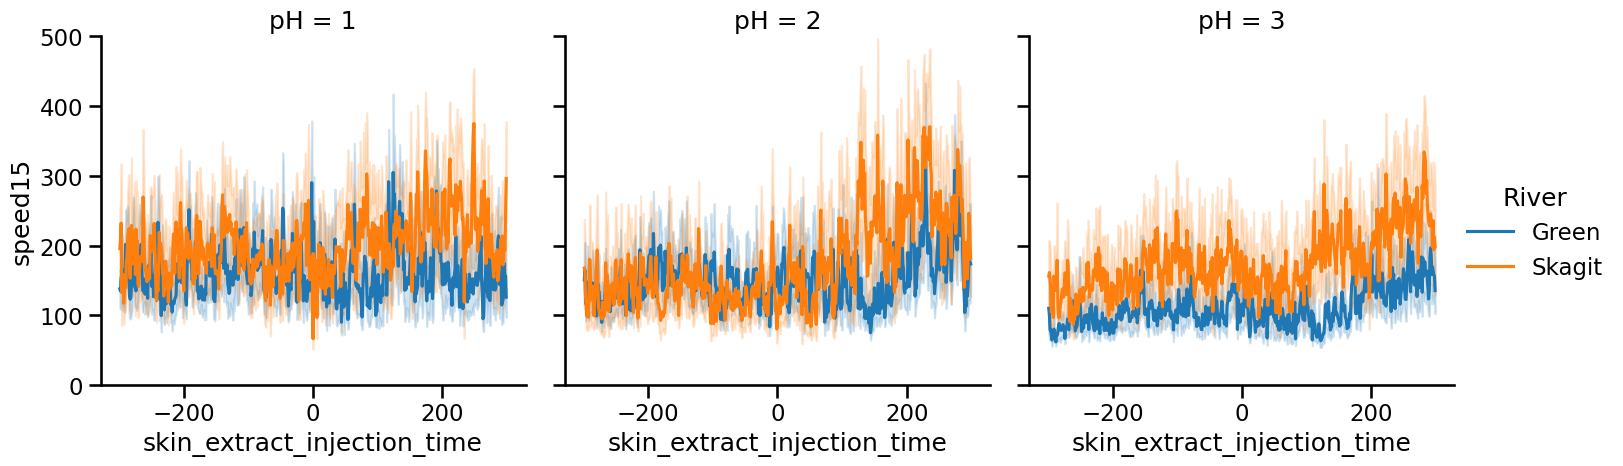

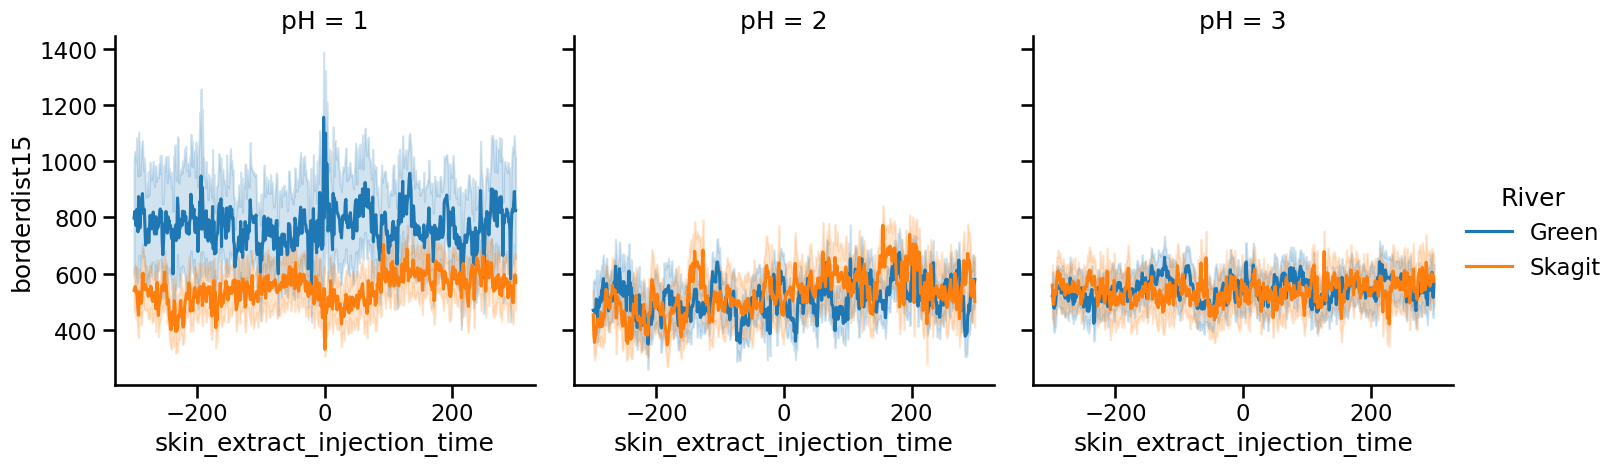

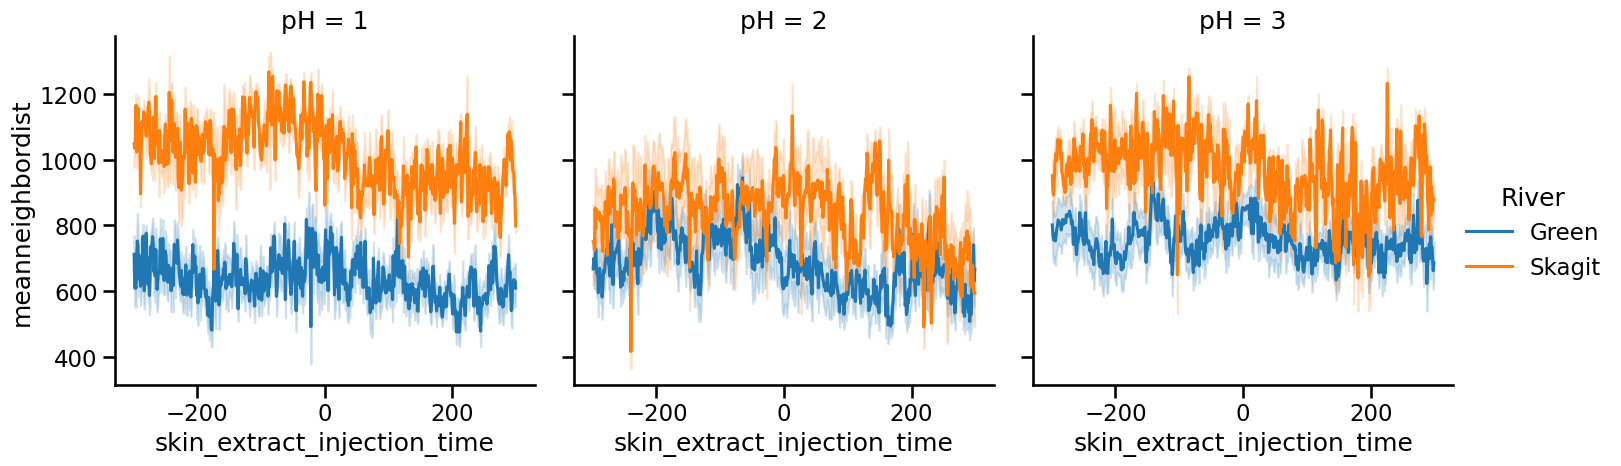

In [193]:
# 5 minutes before and after skin extract injection.

_df = df[
    (df["skin_extract_injection_time"] % 1.0 == 0) &
    (df["skin_extract_injection_time"] > -60 * 5) &
    (df["skin_extract_injection_time"] < 60 * 5)]

p = sns.relplot(data=_df, x="skin_extract_injection_time", y="speed15", kind="line", hue="River", col="pH")
p.set(ylim=[0, 500])
p = sns.relplot(data=_df, x="skin_extract_injection_time", y="borderdist15", kind="line", hue="River", col="pH")
p = sns.relplot(data=_df, x="skin_extract_injection_time", y="meanneighbordist", kind="line", hue="River", col="pH")

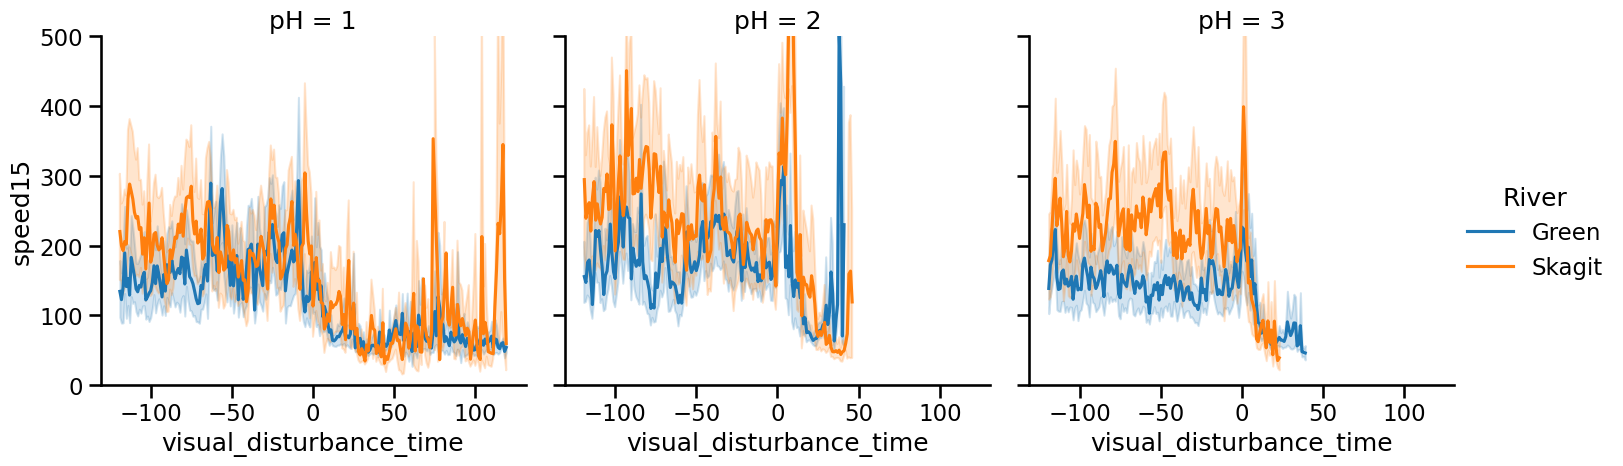

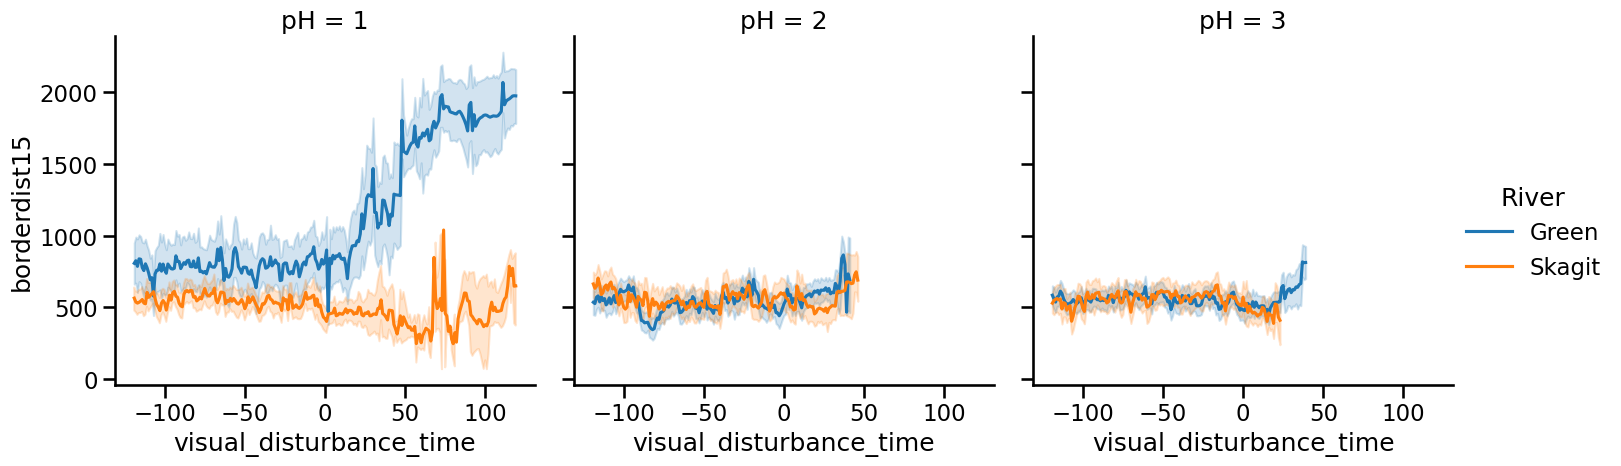

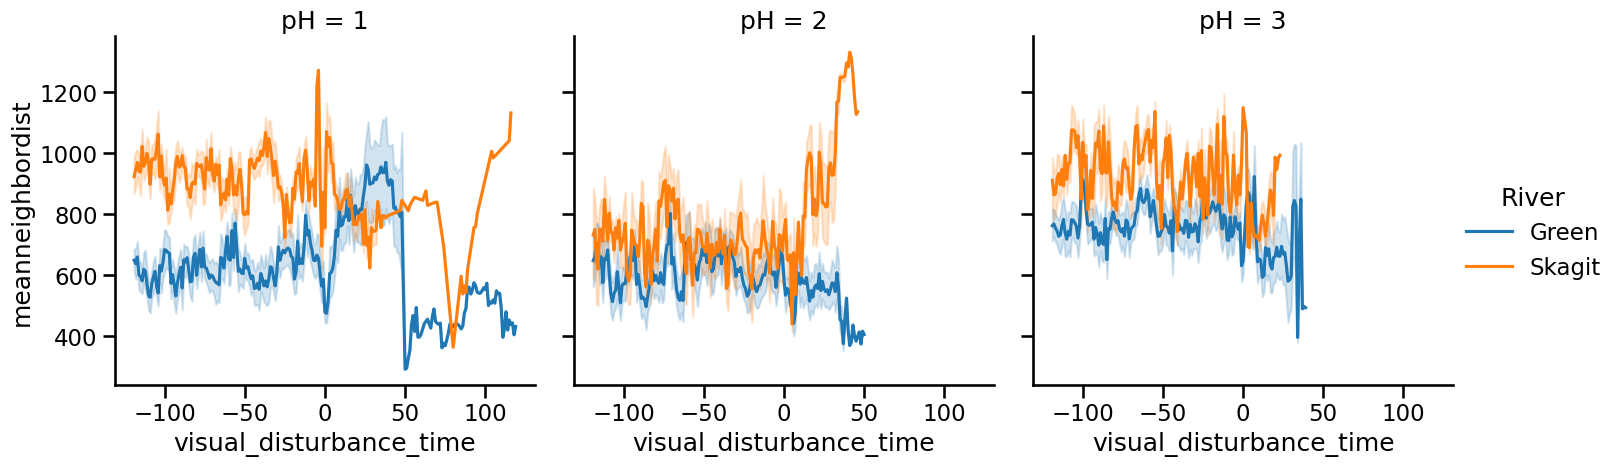

In [192]:
# 5 minutes before and 2 after the visual disturbance.
_df = df[
    (df["visual_disturbance_time"] % 1.0 == 0) &
    (df["visual_disturbance_time"] > -60 * 2) &
    (df["visual_disturbance_time"] < 60 * 2)
    ]

p = sns.relplot(data=_df, x="visual_disturbance_time", y="speed15", kind="line", hue="River", col="pH")
p.set(ylim=[0, 500])
p = sns.relplot(data=_df, x="visual_disturbance_time", y="borderdist15", kind="line", hue="River", col="pH")
p = sns.relplot(data=_df, x="visual_disturbance_time", y="meanneighbordist", kind="line", hue="River", col="pH")


# Step 2. Histogram of variables (speed, mean distance btw neighbors, radial pos)

- first 5 minutes
- 10 minutes leading up to the pheromone
- 3 minutes after the pheromone
- 30 seconds after the startle



In [ ]:
# First 10 minutes
_df = df[
    (df["time"] <= 10 * 60)
]

for var in ["speed15", "borderdist15", "meanneighbordist"]:
    sns.displot(data=_df, x=var, col="River", hue="pH", kind="hist", multiple="dodge", bins=100)

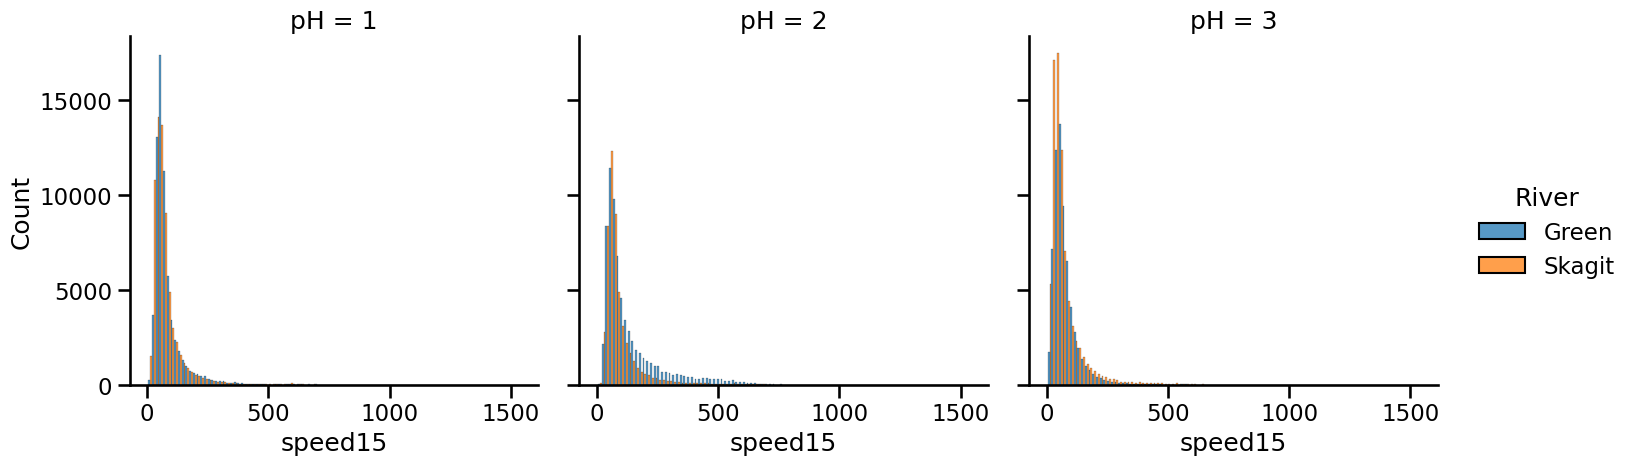

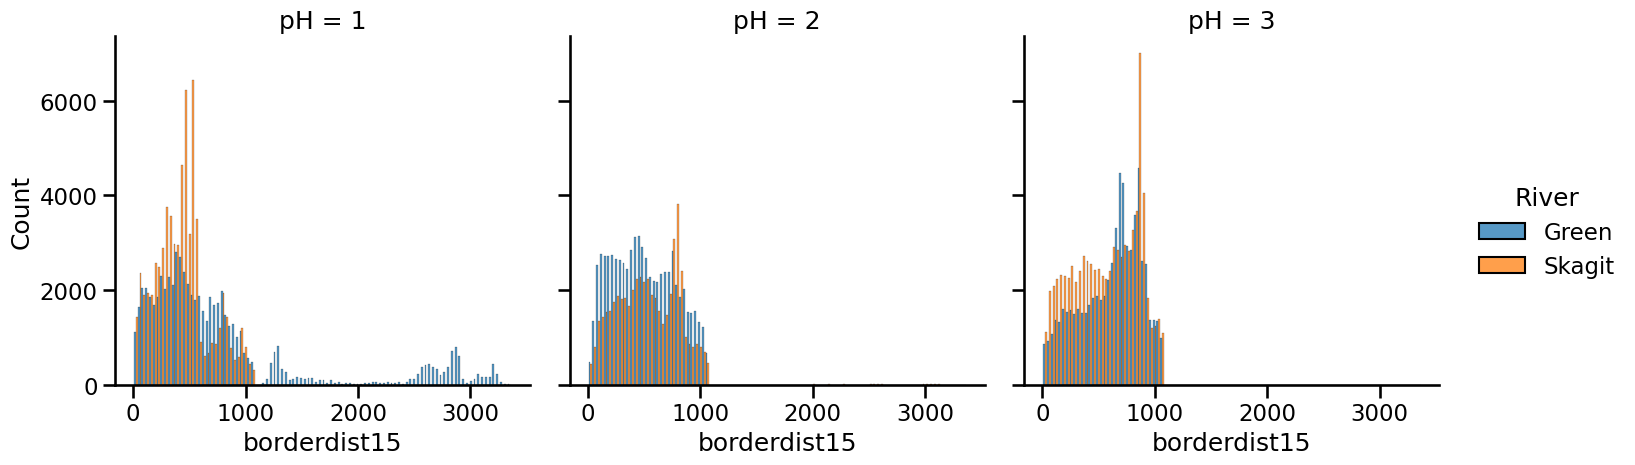

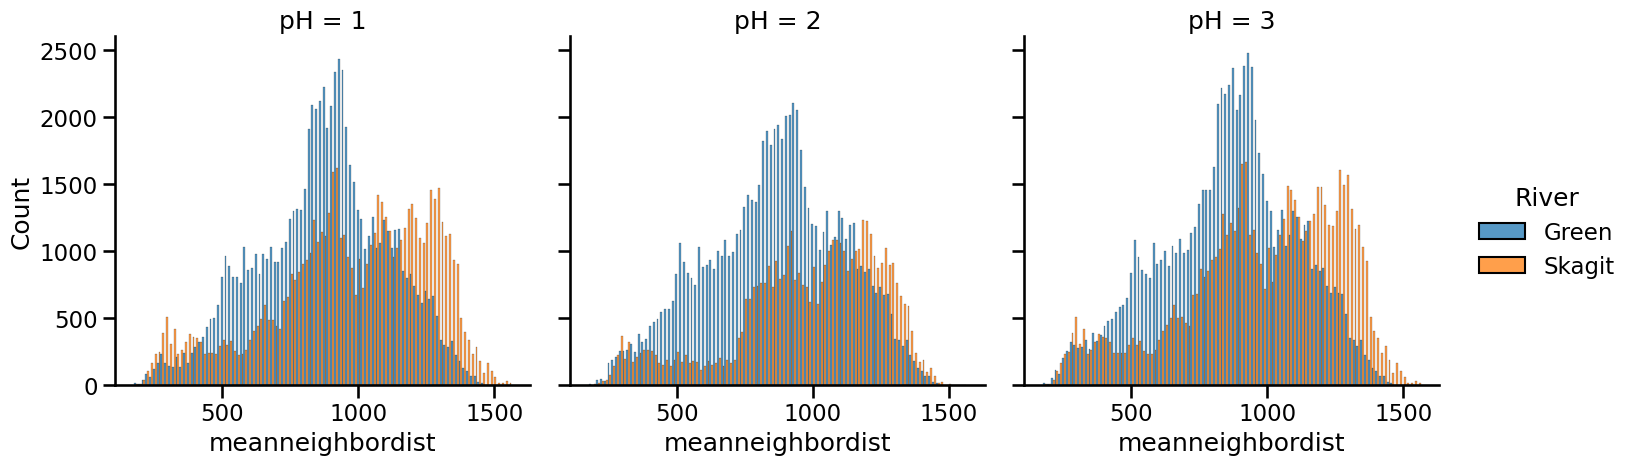

In [140]:
# First 10 minutes
_df = df[
    (df["time"] <= 10 * 60)
]

for var in ["speed15", "borderdist15", "meanneighbordist"]:
    sns.displot(data=_df, x=var, hue="River", col="pH", kind="hist", multiple="dodge", bins=100)

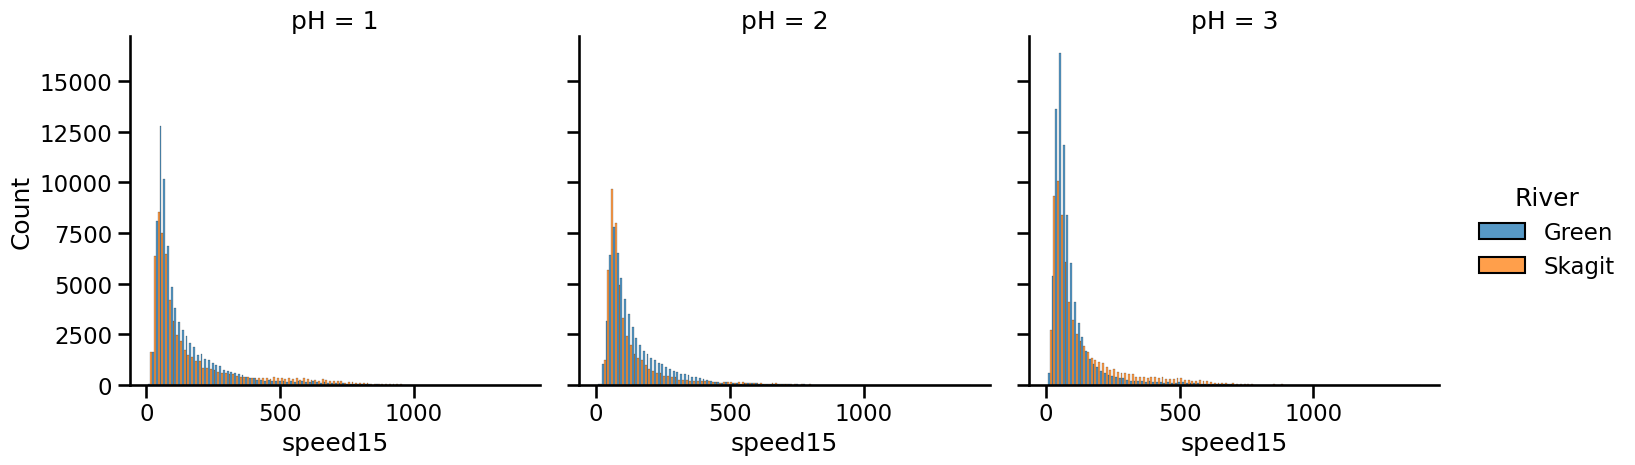

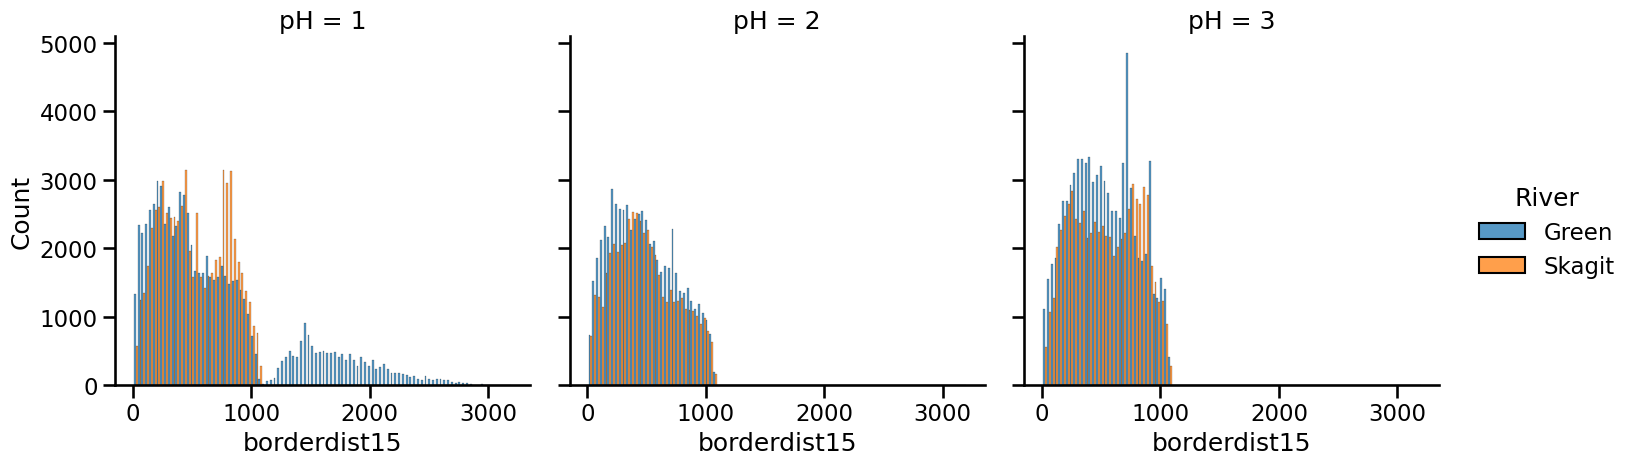

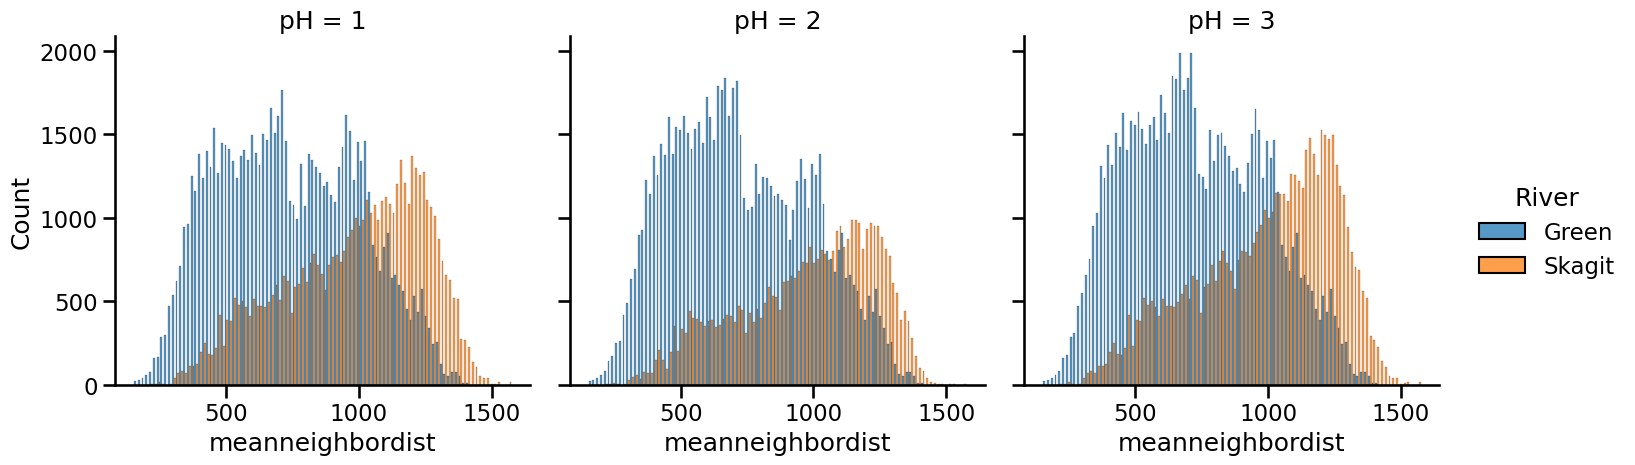

In [141]:
# Before skin extract injection.
_df = df[
    (df["skin_extract_injection_time"] >= -10 * 60) &
    (df["skin_extract_injection_time"] <= 0 * 60)
]

for var in ["speed15", "borderdist15", "meanneighbordist"]:
    sns.displot(data=_df, x=var, hue="River", col="pH", kind="hist", multiple="dodge", bins=100)

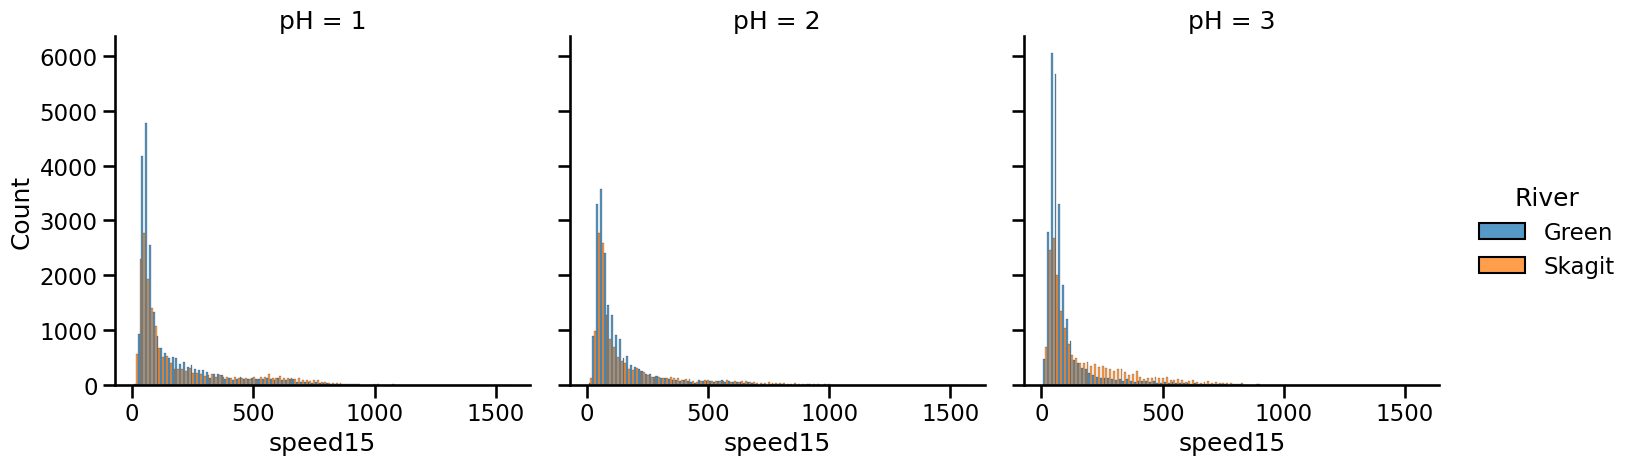

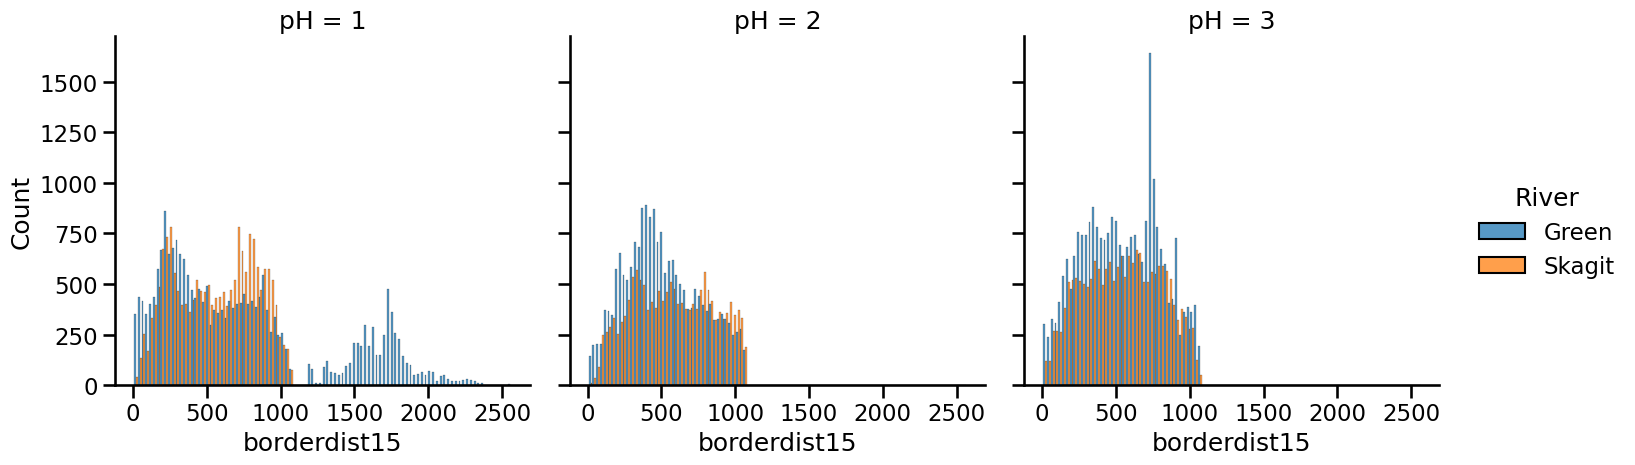

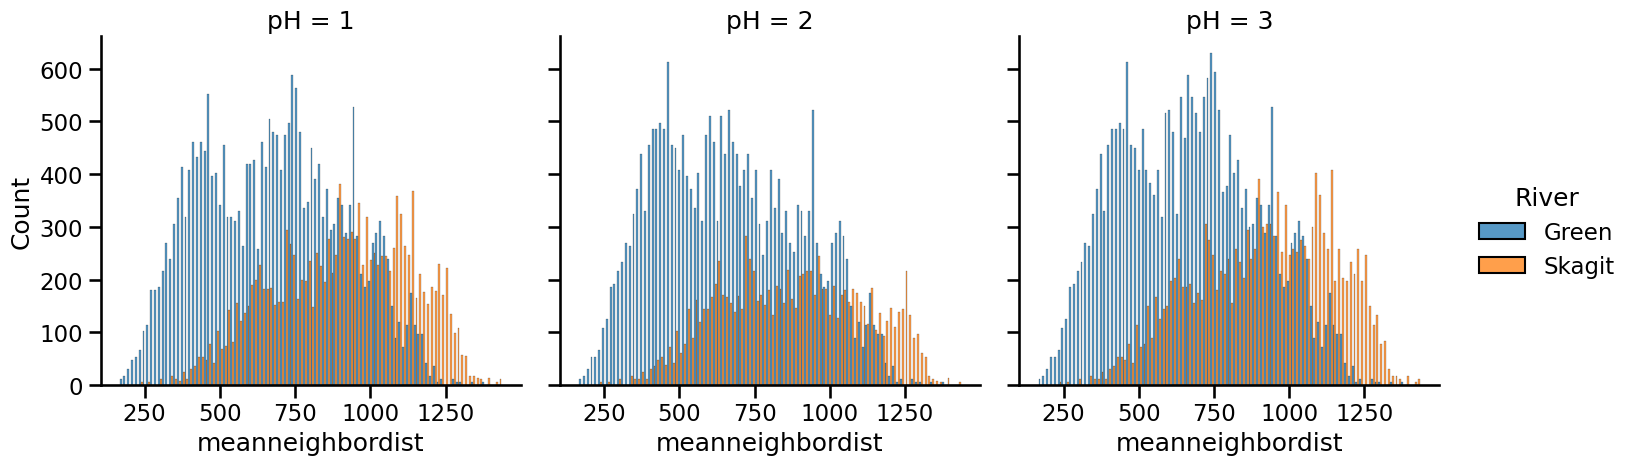

In [142]:
# After skin extract injection.
_df = df[
    (df["skin_extract_injection_time"] >= 0 * 60) &
    (df["skin_extract_injection_time"] <= 3 * 60)
    ]

for var in ["speed15", "borderdist15", "meanneighbordist"]:
    sns.displot(data=_df, x=var, hue="River", col="pH", kind="hist", multiple="dodge", bins=100)

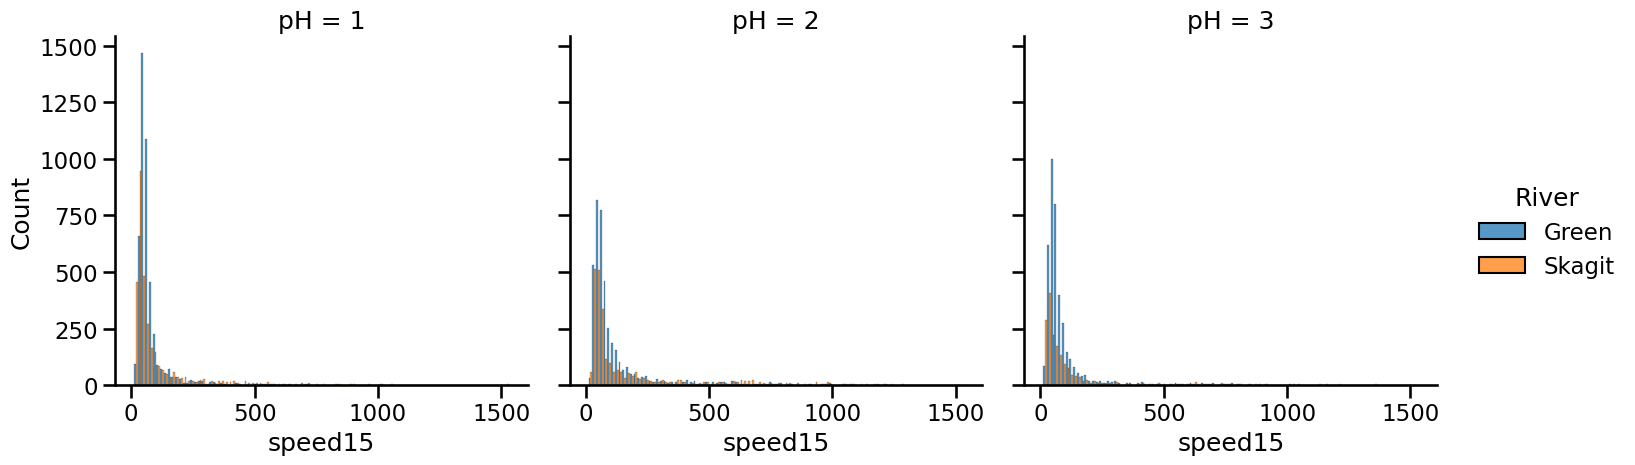

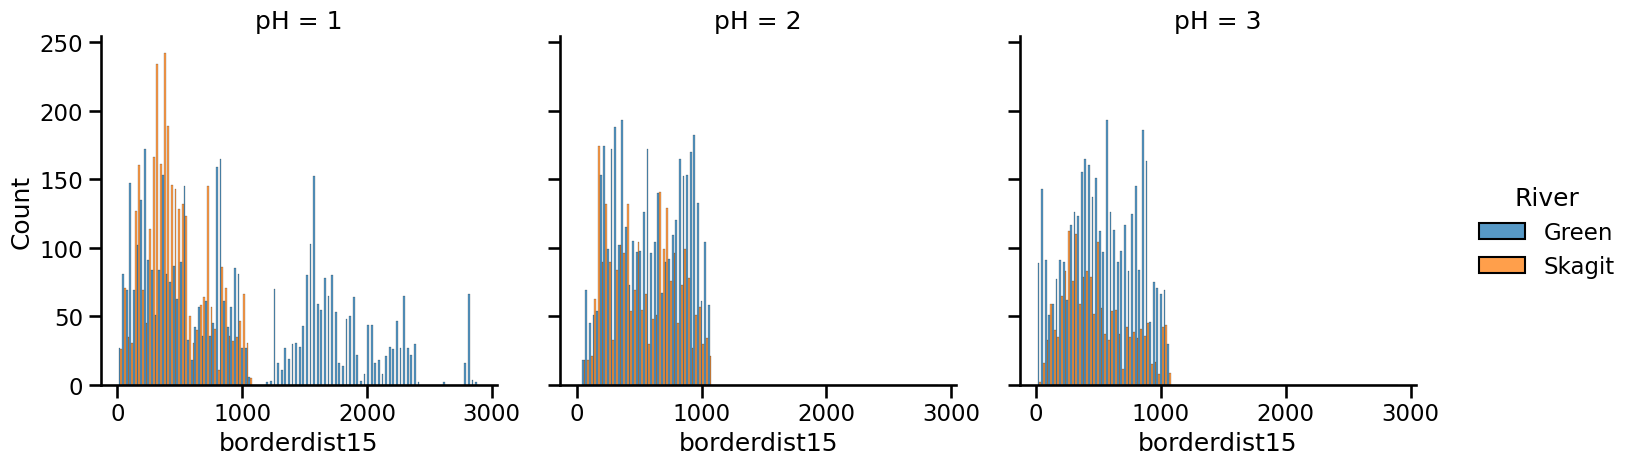

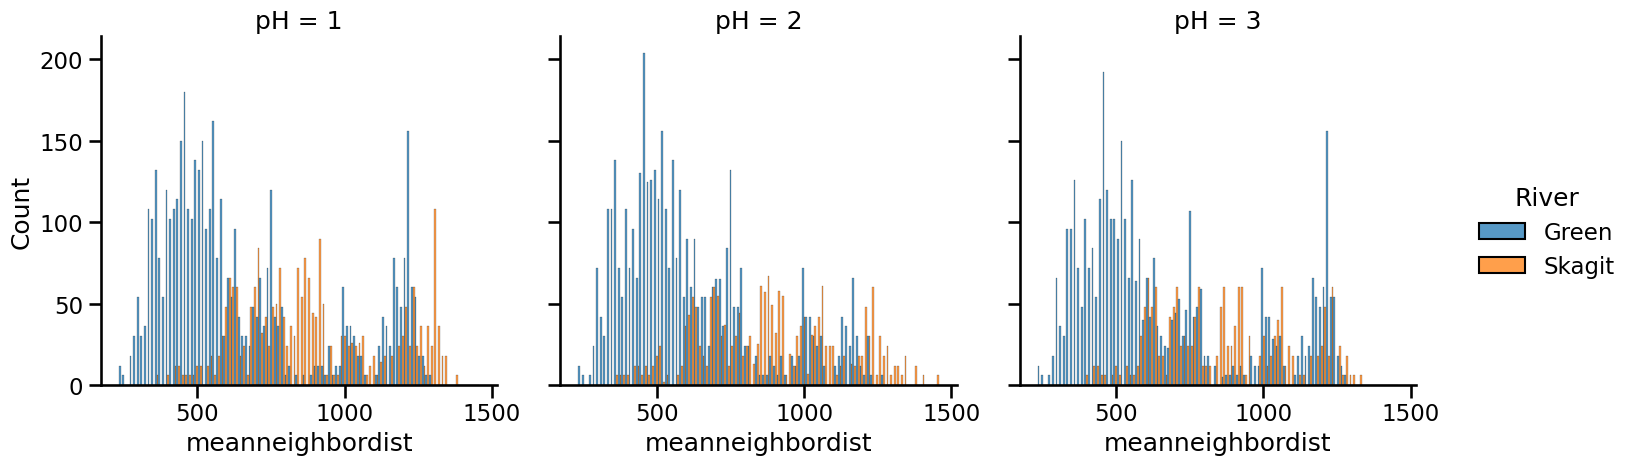

In [143]:
# After visual disturbance.
_df = df[
    (df["visual_disturbance_time"] >= 0 * 60) &
    (df["visual_disturbance_time"] <= 2 * 60)
]

for var in ["speed15", "borderdist15", "meanneighbordist"]:
    sns.displot(data=_df, x=var, hue="River", col="pH", kind="hist", multiple="dodge", bins=100)

# Step 3. Some sort of difference around the pheromone introduction & around the startle

- delta of the histograms between before & after timing
- one for pheromones, one for the startle
- or a histogram of the deltas of the means.
- some way to quantify how the distribution is changing.


In [190]:
# Computes these intervals for before/after skin_extract time
data = []
GROUPBY_VARS = ["River", "pH", "Trial"]
DELTA_VARS = ["speed15", "borderdist15", "meanneighbordist"]
TIME_COL = "skin_extract_injection_time"
WIDTH = 5 * 60 # 5 minute interval around skin extract time


def compute_deltas(df, col_name, interval):
    for group_name, group_df in df.groupby(GROUPBY_VARS):
        before_df = group_df[
            (group_df[col_name] > -1 * interval) &
            (group_df[col_name] < 0)]
        after_df = group_df[
            (group_df[col_name] >= 0) &
            (group_df[col_name] < interval)]
    
        # This is all the column values as a list.
        row = list(group_name)
    
        for delta_var in DELTA_VARS:
            delta = after_df[delta_var].mean() - before_df[delta_var].mean()
            row.append(delta)
            
    
        data.append(row)
    
    deltas_df = pd.DataFrame(data, columns=GROUPBY_VARS + [delta_var + "_delta" for delta_var in DELTA_VARS])
    return deltas_df

skin_extract_deltas = compute_deltas(df, "skin_extract_injection_time", 5 * 60)

visual_disturbance_deltas = compute_deltas(df, "visual_disturbance_time", 2 * 60)

/var/folders/q_/ntb72mmd6jd72ljyc9qyw4100000gn/T/ipykernel_26431/586989673.py:22: RuntimeWarning: invalid value encountered in scalar subtract
  delta = after_df[delta_var].mean() - before_df[delta_var].mean()
/var/folders/q_/ntb72mmd6jd72ljyc9qyw4100000gn/T/ipykernel_26431/586989673.py:22: RuntimeWarning: invalid value encountered in scalar subtract
  delta = after_df[delta_var].mean() - before_df[delta_var].mean()


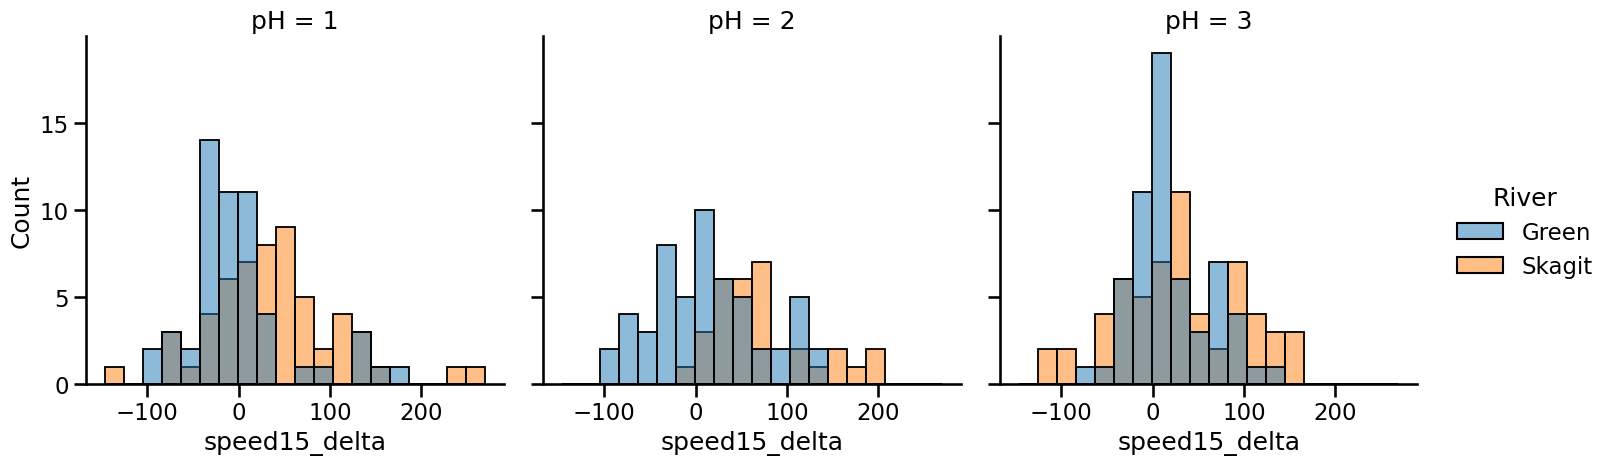

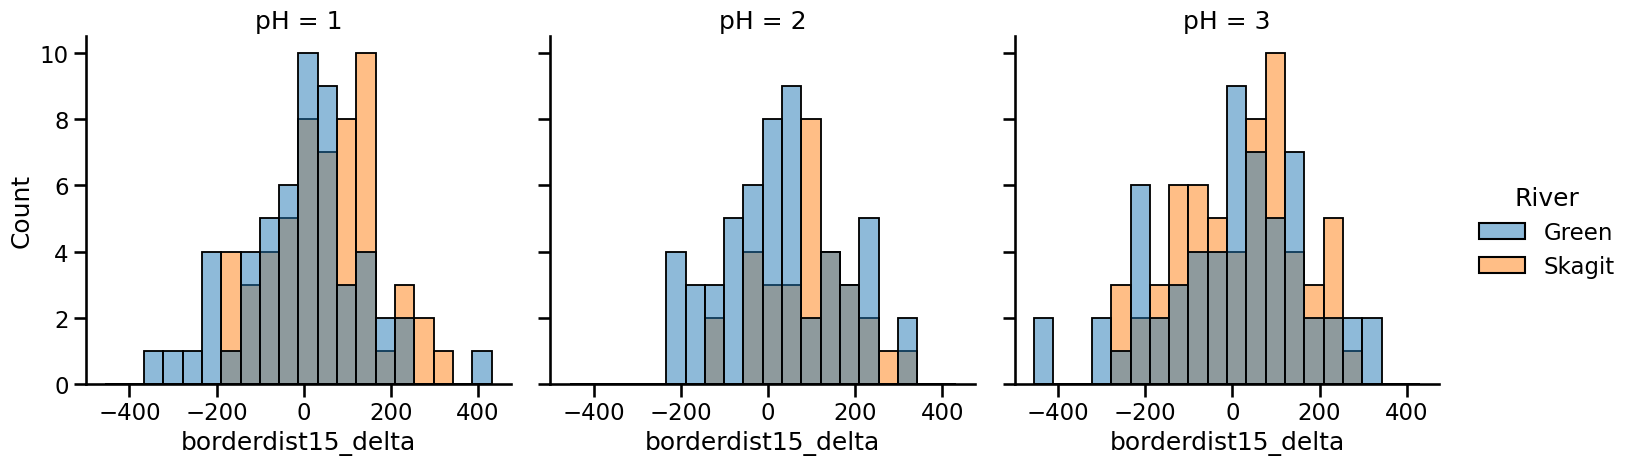

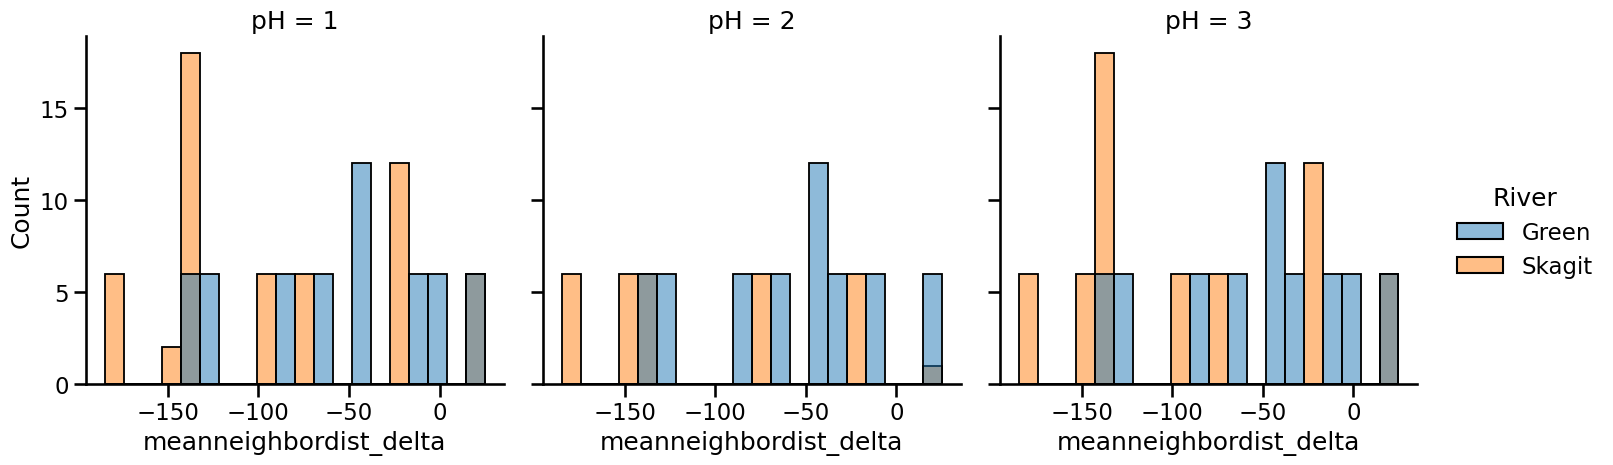

In [132]:
deltas_df = skin_extract_deltas

sns.displot(data=deltas_df, x="speed15_delta", kind="hist", col="pH", hue="River", bins=20)
sns.displot(data=deltas_df, x="borderdist15_delta", kind="hist", col="pH", hue="River", bins=20)
sns.displot(data=deltas_df, x="meanneighbordist_delta", kind="hist", col="pH", hue="River", bins=20)

KeyError: (('hue', 'Skagit'), ('col', np.int64(2)))

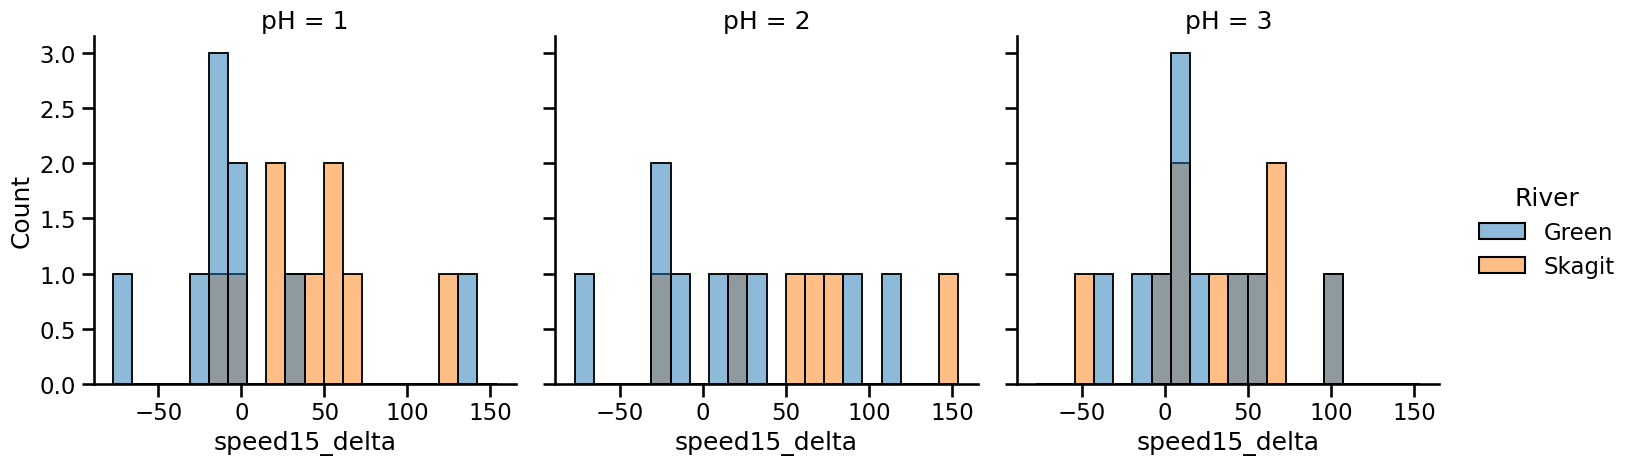

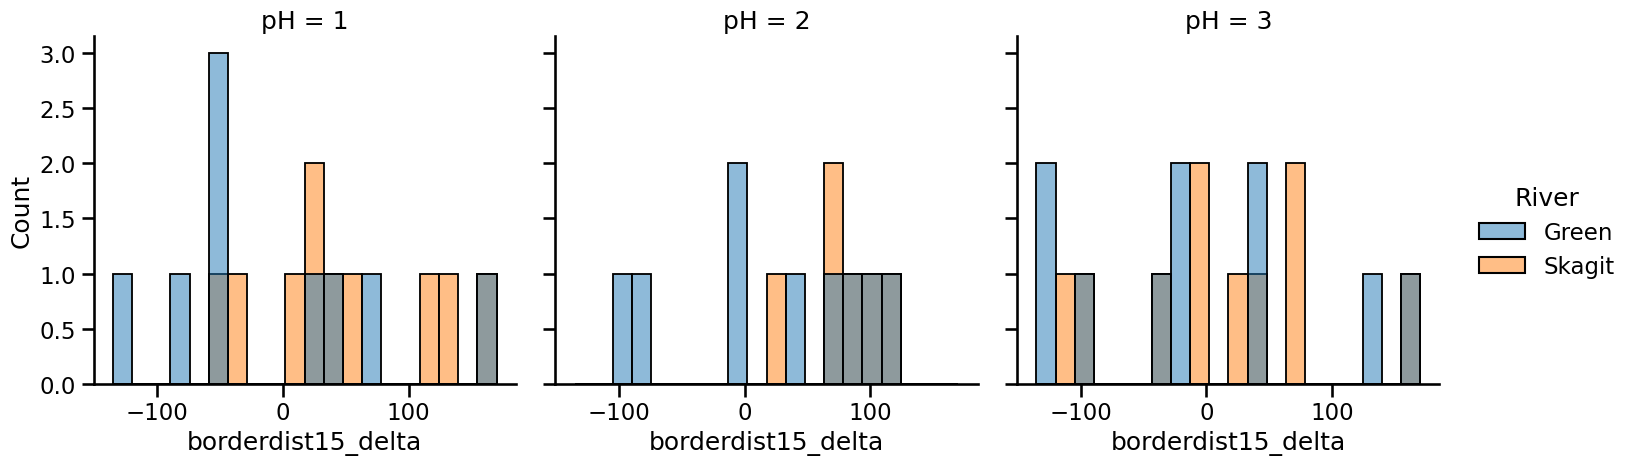

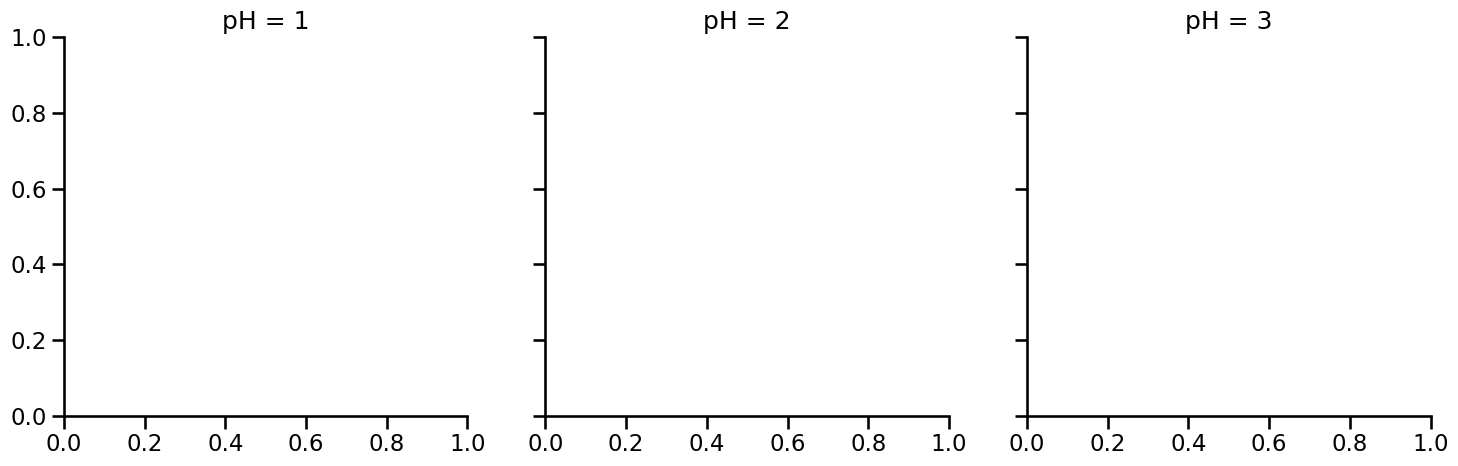

In [191]:
deltas_df = skin_extract_deltas

sns.displot(data=deltas_df, x="speed15_delta", kind="hist", col="pH", hue="River", bins=20)
sns.displot(data=deltas_df, x="borderdist15_delta", kind="hist", col="pH", hue="River", bins=20)
sns.displot(data=deltas_df, x="meanneighbordist_delta", kind="hist", col="pH", hue="River", bins=20)

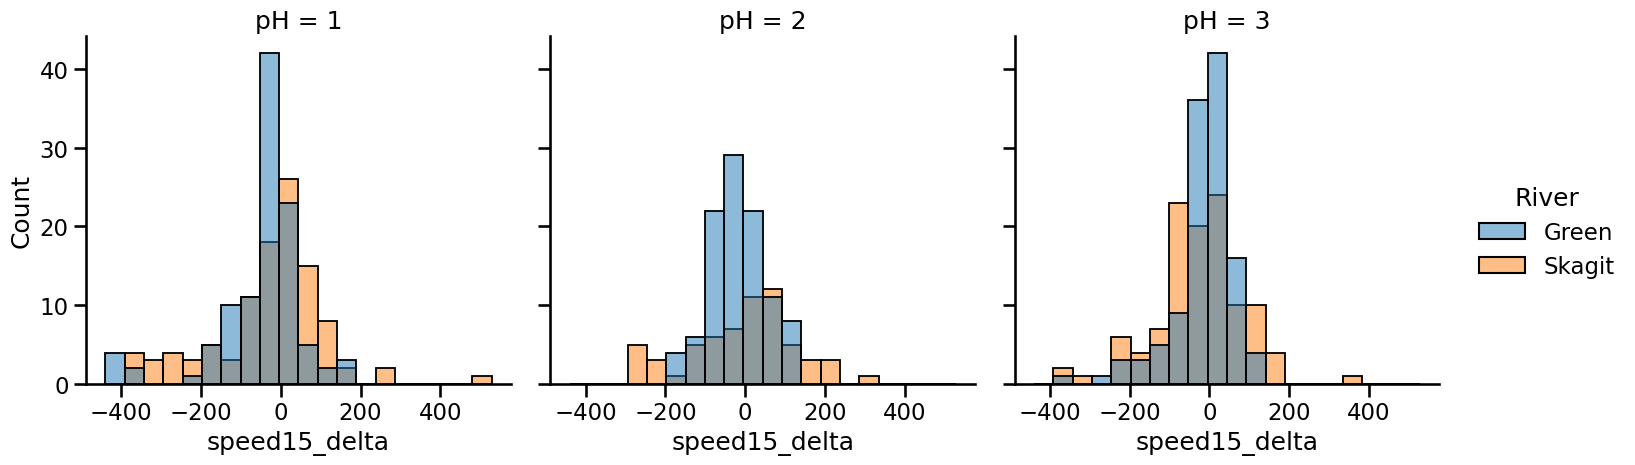

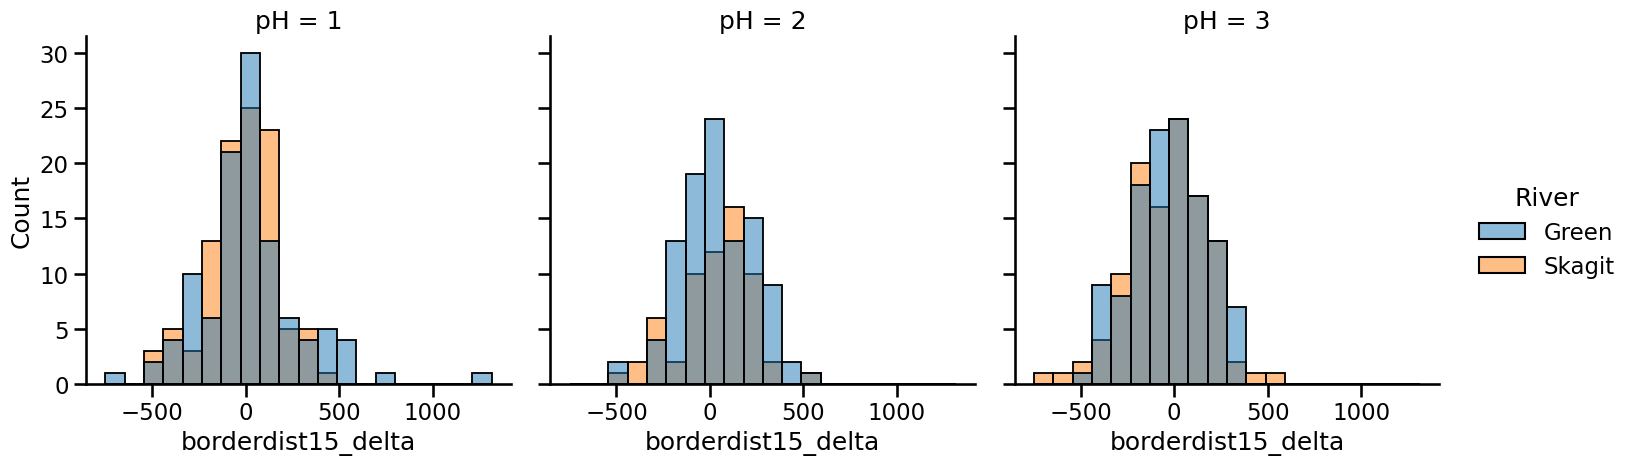

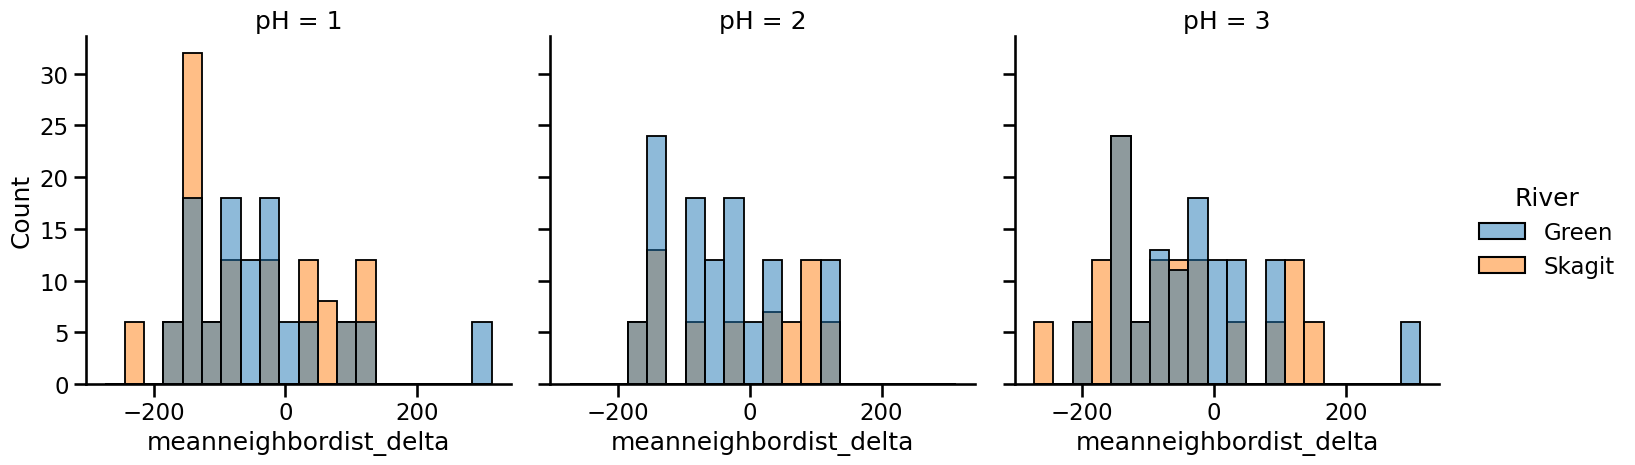

In [148]:
deltas_df = visual_disturbance_deltas

sns.displot(data=deltas_df, x="speed15_delta", kind="hist", col="pH", hue="River", bins=20)
sns.displot(data=deltas_df, x="borderdist15_delta", kind="hist", col="pH", hue="River", bins=20)
sns.displot(data=deltas_df, x="meanneighbordist_delta", kind="hist", col="pH", hue="River", bins=20)